# 04 — Classical ML Baselines | CIC-IDS2017 (Kaggle, shared pilot split)

Huấn luyện **Random Forest, XGBoost, LightGBM v2** trên **chính xác** tập dữ liệu đã chia trong notebook **03_Gaussian_Anomaly**. Dùng 15 nhãn gốc cho multiclass; báo cáo thêm binary BENIGN/ATTACK để có thể đối chiếu Gaussian (không so sánh trực tiếp multiclass macro-F1 với binary F1).

**Phương pháp:** không lấy mẫu/chia dữ liệu lại; imputer chỉ `fit` trên `train`, chỉ dùng validation để kiểm tra; các tham số mô hình được định sẵn và test không tham gia chọn mô hình. Đường chia 60/20/20 được tạo ở notebook 03 bằng **binary-stratified random split**; do thiếu timestamp, IP, flow ID, kết quả chỉ là **exploratory pilot, không phải leakage-safe benchmark**. Các lớp cực hiếm có thể phân bố không đồng đều.

**Trước khi chạy:** Trong Kaggle, **Add Input** → chọn **output của notebook 03** (notebook 03 phải được Save Version), hoặc chạy cùng session nơi file đã tồn tại ở `/kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet`. Notebook này không cần ZIP/source dataset gốc để huấn luyện trên split được lưu.

## 1. Cấu hình & xác định artifact từ notebook 03

In [30]:
from pathlib import Path
import json, sys, hashlib, time
import numpy as np
import pandas as pd

SEED = 42
OUTPUT = Path('/kaggle/working/nids_outputs/04_ML_Baselines') if Path('/kaggle/working').exists() else Path('reports/notebook_outputs/04_ML_Baselines')
OUTPUT.mkdir(parents=True, exist_ok=True)

# Nếu có nhiều output notebook 03 được gắn, điền chính xác đường dẫn tại đây.
SPLIT_PATH = None  # ví dụ: '/kaggle/input/.../cic_pilot_splits.parquet'

if SPLIT_PATH is None:
    preferred = Path('/kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet')
    if preferred.is_file():
        split_path = preferred
    else:
        candidates = sorted(Path('/kaggle/input').rglob('cic_pilot_splits.parquet')) if Path('/kaggle/input').exists() else []
        if not candidates:
            raise FileNotFoundError(
                'Không tìm thấy cic_pilot_splits.parquet. Hãy mở notebook 03, Save Version; '
                'sau đó Add Input output của notebook 03 vào notebook 04. Không tự chia tập lại.'
            )
        if len(candidates) > 1:
            raise RuntimeError(f'Có nhiều split artifacts. Hãy đặt SPLIT_PATH cụ thể:\n' + '\n'.join(map(str, candidates)))
        split_path = candidates[0]
else:
    split_path = Path(SPLIT_PATH)
    if not split_path.is_file():
        raise FileNotFoundError(split_path)

print('Split artifact:', split_path)
print('Size (MiB):', round(split_path.stat().st_size/2**20, 2))
print('SHA-256:', hashlib.sha256(split_path.read_bytes()).hexdigest())

Split artifact: /kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet
Size (MiB): 0.75
SHA-256: 14304c159bdd8ffecd321fe4e132db4f71b921a36c6b5f56fd51cf363ef42b7b


## 2. Đọc và xác minh nhãn, feature và split — tuyệt đối không chia lại

In [31]:
from sklearn.preprocessing import LabelEncoder

sample = pd.read_parquet(split_path)
required = {'Label', '_split', '_binary_label'}
if not required.issubset(sample.columns):
    raise ValueError(f'Split thiếu cột: {sorted(required-set(sample.columns))}')

# Loại cột metadata / target, giữ đúng thứ tự feature trong artifact.
features = [c for c in sample.columns if c not in {'Label', '_split', '_binary_label'}]
if not features:
    raise ValueError('Không có feature trong split artifact')
if len(features) != 19:
    raise ValueError(f'Dự kiến 19 feature từ notebook 03, nhưng nhận {len(features)}: {features}')

split = sample['_split'].astype(str)
if not split.isin(['train', 'validation', 'test']).all():
    raise ValueError('Phát hiện giá trị _split không hợp lệ')
if (split.value_counts().reindex(['train','validation','test'], fill_value=0) == 0).any():
    raise ValueError('Train/validation/test không được để trống')

labels = sample['Label'].astype(str)
binary_check = (labels != 'BENIGN').astype(int)
if not np.array_equal(sample['_binary_label'].astype(int).to_numpy(), binary_check.to_numpy()):
    raise ValueError('_binary_label không khớp Label')

train_mask = split.eq('train').to_numpy()
val_mask = split.eq('validation').to_numpy()
test_mask = split.eq('test').to_numpy()

train_labels = set(labels[train_mask]); all_labels = set(labels)
if train_labels != all_labels:
    raise ValueError(f'Có lớp chưa xuất hiện trong TRAIN: {sorted(all_labels-train_labels)}. '
                     'Không được đưa test/validation vào train. Cần sửa giao thức split tại notebook 03 rồi chạy lại cả hai.')
enc = LabelEncoder().fit(labels[train_mask])
y_train = enc.transform(labels[train_mask])
y_val = enc.transform(labels[val_mask])
y_test = enc.transform(labels[test_mask])

# Clean ký hiệu inf và chuỗi bất thường; không dùng val/test để fit tham số.
X = sample[features].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
X_train, X_val, X_test = X.loc[train_mask], X.loc[val_mask], X.loc[test_mask]
print('Total:', len(sample), '| Features:', len(features), '| Classes:', len(enc.classes_))
print('Train:',len(X_train),'Validation:',len(X_val),'Test:',len(X_test))
print('NaN/invalid feature values:', int(X.isna().sum().sum()))
print('\nSplit-by-label counts (includes rare classes):')
display(pd.crosstab(labels, split).reindex(columns=['train','validation','test'], fill_value=0))

Total: 15720 | Features: 19 | Classes: 15
Train: 9432 Validation: 3144 Test: 3144
NaN/invalid feature values: 38

Split-by-label counts (includes rare classes):


_split,train,validation,test
Label,,,
BENIGN,3000,1000,1000
Bot,597,190,213
DDoS,585,212,203
DoS GoldenEye,611,180,209
DoS Hulk,630,180,190
DoS Slowhttptest,595,203,202
DoS slowloris,611,208,181
FTP-Patator,592,200,208
Heartbleed,6,3,2


## 3. Khai báo baseline và cấu hình cố định

Cấu hình RF/XGB theo pilot trước đây; **LightGBM v2** theo bản sửa đã thử thành công trên WSL. Cả ba dùng cùng 19 feature, cùng train/validation/test; imputation median `fit` trên tập train. Không tuning tham số bằng test.

In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

model_configs = {
    'RandomForest': RandomForestClassifier(
        n_estimators=80, min_samples_leaf=2, class_weight='balanced_subsample',
        n_jobs=2, random_state=SEED),
    'XGBoost': XGBClassifier(
        n_estimators=80, max_depth=5, n_jobs=2, random_state=SEED,
        eval_metric='mlogloss'),
    'LightGBM': LGBMClassifier(
        objective='multiclass', n_estimators=150, learning_rate=0.05,
        num_leaves=15, max_depth=6, min_child_samples=30,
        reg_lambda=1.0, n_jobs=2, random_state=SEED, verbosity=-1),
}
print('Models:', ', '.join(model_configs))

Models: RandomForest, XGBoost, LightGBM


## 4. Train và đánh giá — không dùng test để chọn cấu hình

In [33]:
import joblib
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

metrics_rows = []
trained = {}
class_indices = np.arange(len(enc.classes_))

def score_split(name, section, y_true, y_pred):
    metrics_rows.append({
        'model':name, 'split':section, 'samples':len(y_true),
        'accuracy':float(accuracy_score(y_true,y_pred)),
        'macro_f1':float(f1_score(y_true,y_pred,labels=class_indices,average='macro',zero_division=0)),
        'weighted_f1':float(f1_score(y_true,y_pred,labels=class_indices,average='weighted',zero_division=0)),
        'binary_attack_precision':float(precision_score(y_true!=enc.transform(['BENIGN'])[0], y_pred!=enc.transform(['BENIGN'])[0],zero_division=0)),
        'binary_attack_recall':float(recall_score(y_true!=enc.transform(['BENIGN'])[0], y_pred!=enc.transform(['BENIGN'])[0],zero_division=0)),
        'binary_attack_f1':float(f1_score(y_true!=enc.transform(['BENIGN'])[0], y_pred!=enc.transform(['BENIGN'])[0],zero_division=0)),
    })

assert 'BENIGN' in enc.classes_, 'Không có nhãn BENIGN'
for name, estimator in model_configs.items():
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('model', estimator),
    ])
    print(f'\n--- {name}: training ---')
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_seconds = time.perf_counter()-start
    trained[name] = pipe

    val_pred = np.asarray(pipe.predict(X_val),dtype=int)
    test_pred = np.asarray(pipe.predict(X_test),dtype=int)
    score_split(name, 'validation', y_val, val_pred)
    score_split(name, 'test', y_test, test_pred)

    report = classification_report(y_test, test_pred, labels=class_indices,
                                   target_names=enc.classes_, zero_division=0, output_dict=True)
    (OUTPUT/f'{name}_test_classification_report.json').write_text(
        json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
    np.save(OUTPUT/f'{name}_test_confusion_matrix.npy',
            confusion_matrix(y_test, test_pred, labels=class_indices))
    pd.DataFrame({'actual_label':enc.inverse_transform(y_test),
                  'predicted_label':enc.inverse_transform(test_pred),
                  'actual_attack':(enc.inverse_transform(y_test)!='BENIGN').astype(int),
                  'predicted_attack':(enc.inverse_transform(test_pred)!='BENIGN').astype(int)}).to_csv(
                      OUTPUT/f'{name}_test_predictions.csv',index=False)
    joblib.dump({'pipeline':pipe,'label_encoder':enc,'features':features,
                 'train_seconds':train_seconds,'protocol':'SHARED_CIC_BINARY_STRATIFIED_RANDOM_PILOT_NOT_LEAKAGE_SAFE'},
                OUTPUT/f'{name}.joblib')
    print(f'{name}: fit {train_seconds:.2f}s | test macro-F1 {metrics_rows[-1]["macro_f1"]:.4f}')

metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df.sort_values(['split','macro_f1'],ascending=[True,False]).round(4))
metrics_df.to_csv(OUTPUT/'baseline_metrics.csv',index=False)


--- RandomForest: training ---
RandomForest: fit 1.10s | test macro-F1 0.8763

--- XGBoost: training ---
XGBoost: fit 1.42s | test macro-F1 0.8727

--- LightGBM: training ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM: fit 1.97s | test macro-F1 0.8764


,model,split,samples,accuracy,macro_f1,weighted_f1,binary_attack_precision,binary_attack_recall,binary_attack_f1
5,LightGBM,test,3144,0.9431,0.8764,0.9415,0.9897,0.9907,0.9902
1,RandomForest,test,3144,0.9396,0.8763,0.9394,0.9811,0.9944,0.9877
3,XGBoost,test,3144,0.9424,0.8727,0.9413,0.9884,0.9897,0.9890
2,XGBoost,validation,3144,0.9415,0.8970,0.9401,0.9902,0.9921,0.9911
4,LightGBM,validation,3144,0.9427,0.8868,0.9413,0.9902,0.9930,0.9916
0,RandomForest,validation,3144,0.9348,0.8823,0.9350,0.9838,0.9930,0.9884


## 5. Confusion matrices và bảng so sánh trên cùng tập test

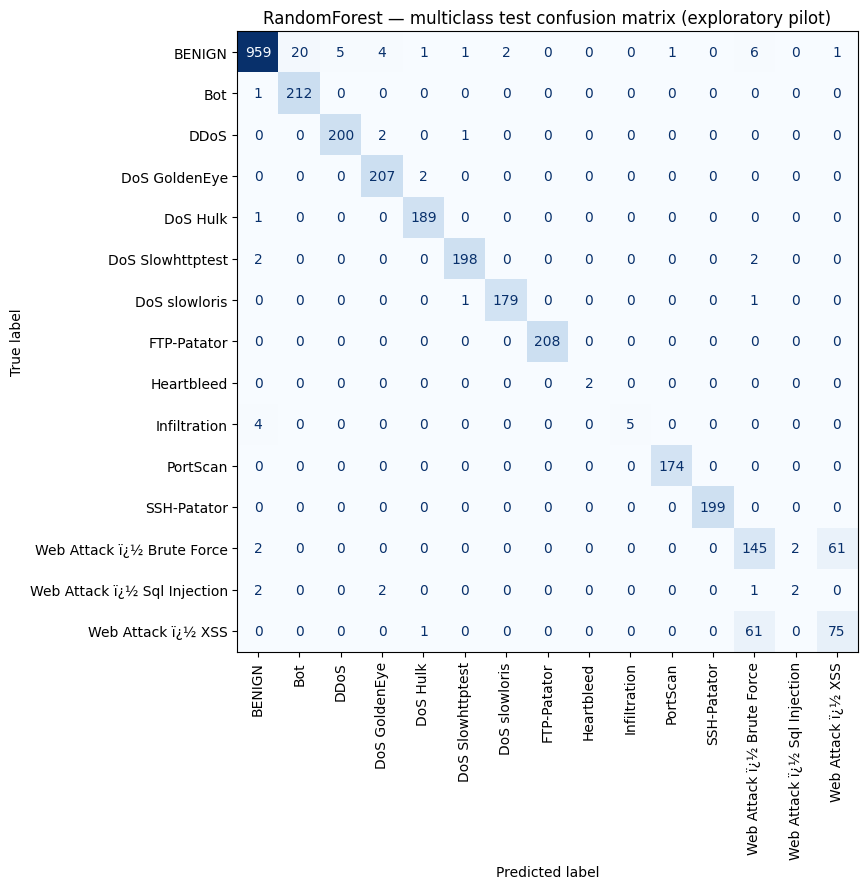

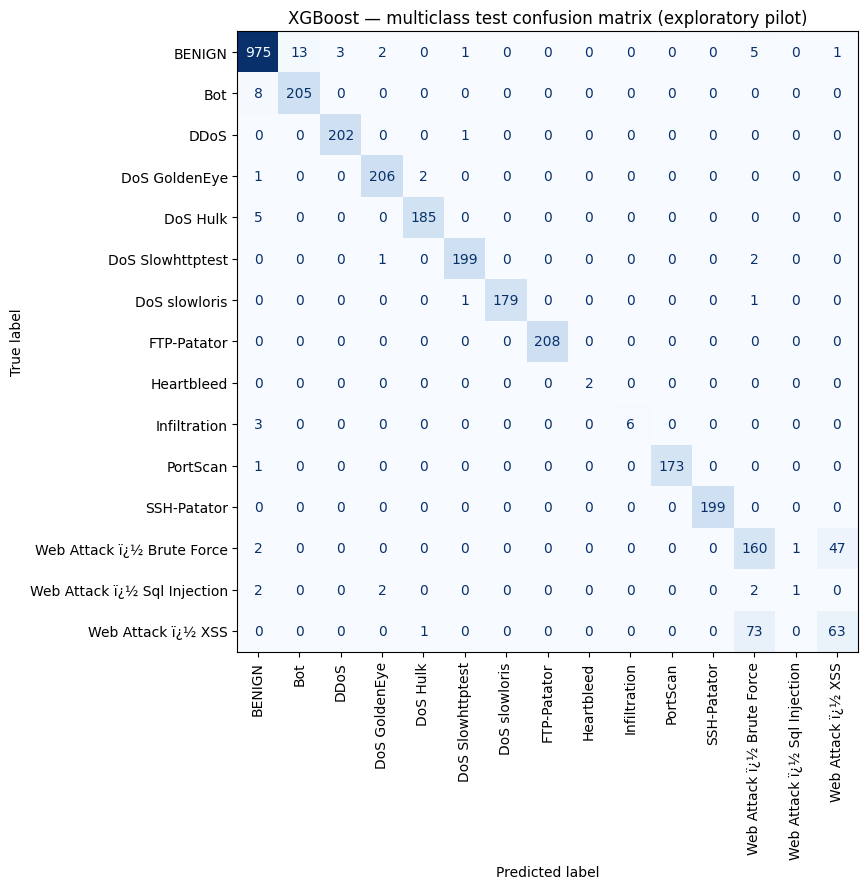

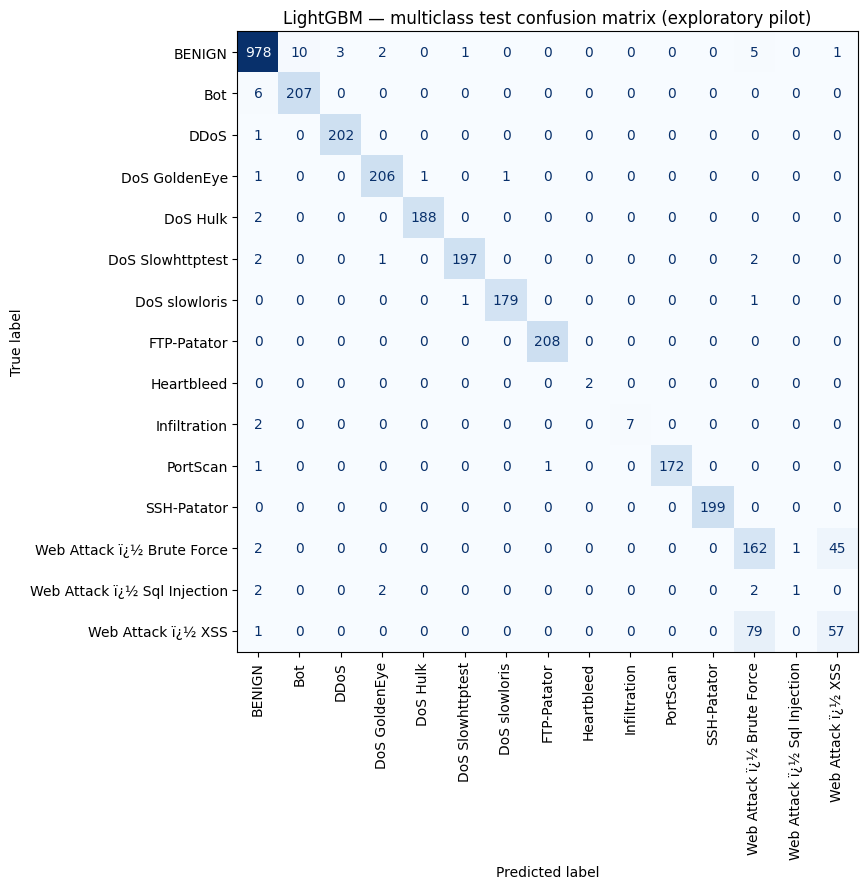

,model,accuracy,macro_f1,weighted_f1,binary_attack_precision,binary_attack_recall,binary_attack_f1
5,LightGBM,0.9431,0.8764,0.9415,0.9897,0.9907,0.9902
1,RandomForest,0.9396,0.8763,0.9394,0.9811,0.9944,0.9877
3,XGBoost,0.9424,0.8727,0.9413,0.9884,0.9897,0.9890


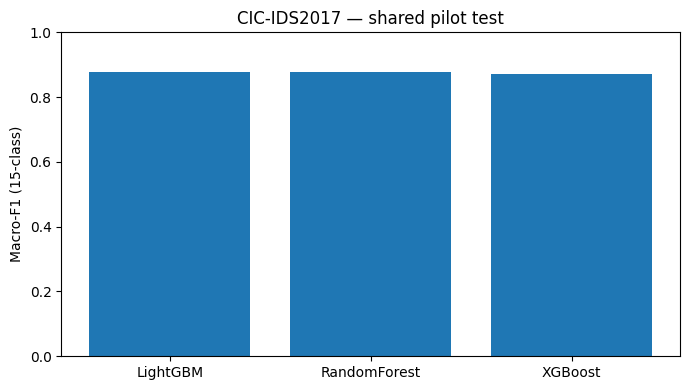

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name in model_configs:
    cm = np.load(OUTPUT/f'{name}_test_confusion_matrix.npy')
    fig, ax = plt.subplots(figsize=(11, 9))
    ConfusionMatrixDisplay(cm, display_labels=enc.classes_).plot(
        ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{name} — multiclass test confusion matrix (exploratory pilot)')
    fig.tight_layout()
    fig.savefig(OUTPUT/f'{name}_test_confusion_matrix.png',dpi=130,bbox_inches='tight')
    plt.show()

test_table = metrics_df.query("split == 'test'").sort_values('macro_f1',ascending=False)
cols = ['model','accuracy','macro_f1','weighted_f1',
        'binary_attack_precision','binary_attack_recall','binary_attack_f1']
display(test_table[cols].round(4))
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(test_table['model'],test_table['macro_f1'])
ax.set_ylim(0,1)
ax.set_ylabel('Macro-F1 (15-class)')
ax.set_title('CIC-IDS2017 — shared pilot test')
fig.tight_layout()
fig.savefig(OUTPUT/'baseline_macro_f1_comparison.png',dpi=150)
plt.show()

## 6. Lưu manifest và xác nhận artifact

In [35]:
manifest = {
    'dataset':'CIC-IDS2017',
    'split_source':str(split_path),
    'split_sha256':hashlib.sha256(split_path.read_bytes()).hexdigest(),
    'rows':len(sample),
    'feature_names':features,
    'class_names':enc.classes_.tolist(),
    'split_counts':split.value_counts().to_dict(),
    'model_configs':{k:v.get_params() for k,v in model_configs.items()},
    'protocol':'SHARED_CIC_BINARY_STRATIFIED_RANDOM_PILOT_NOT_LEAKAGE_SAFE',
    'limitations':[
        'CSV lacks timestamp/IP/flow ID; no host/event/time-disjoint evaluation',
        'Gaussian notebook split stratified by binary label, not 15-class labels',
        'Pilot class distribution differs from real network traffic',
        'Test metrics are exploratory only',
    ],
}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2,default=str,ensure_ascii=False),encoding='utf-8')
print('Saved outputs:', OUTPUT)
for p in sorted(OUTPUT.iterdir()): print(' -',p.name)
print('\nNhớ Save Version để giữ các artifacts và dùng trong notebook 09.')

Saved outputs: /kaggle/working/nids_outputs/04_ML_Baselines
 - LightGBM.joblib
 - LightGBM_test_classification_report.json
 - LightGBM_test_confusion_matrix.npy
 - LightGBM_test_confusion_matrix.png
 - LightGBM_test_predictions.csv
 - RandomForest.joblib
 - RandomForest_test_classification_report.json
 - RandomForest_test_confusion_matrix.npy
 - RandomForest_test_confusion_matrix.png
 - RandomForest_test_predictions.csv
 - XGBoost.joblib
 - XGBoost_test_classification_report.json
 - XGBoost_test_confusion_matrix.npy
 - XGBoost_test_confusion_matrix.png
 - XGBoost_test_predictions.csv
 - baseline_macro_f1_comparison.png
 - baseline_metrics.csv
 - experiment_manifest.json

Nhớ Save Version để giữ các artifacts và dùng trong notebook 09.
